# LIVRABLE FINAL : Tournées de livraison avec capacités et fenêtres horaires (CVRPTW)

**Projet CesiCDP / ADEME**

**Groupe 1 : Sandago, Emmanuel, Thomas**

## Sommaire

- Introduction
- Chapitre I – Modélisation mathématique
- Chapitre II – Des méthodes exactes aux métaheuristiques
- Chapitre III – Choix de la métaheuristique : la recherche tabou
- Chapitre IV – Réalisation
- Chapitre V – Résultats, expérimentations et analyse
- Conclusion et recommandations
- Références

Le code est dans `cvrptw_analyse_solomon.py`, les cas de test dans `tests_cvrptw.py`, et les résultats des études dans le dossier `resultats_cvrptw/`.

# INTRODUCTION

Dans le cadre de sa politique de réduction de la consommation d'énergie et des émissions de gaz à effet de serre, l'ADEME souhaite soutenir de nouvelles solutions de mobilité.

CesiCDP propose d'étudier l'optimisation de tournées de livraison. Le but est de planifier les trajets d'une flotte de camions qui dessert un ensemble de clients, en **minimisant la durée totale des tournées**.

Le contexte ADEME évoque un trafic variable selon les tranches horaires. Nous retenons des **temps de trajet fixes** et étudions la variante **CVRPTW** : capacité des camions et fenêtres horaires de livraison.

Ce livrable reprend la modélisation du livrable 1, corrigée, puis présente la méthode retenue (la recherche tabou), sa réalisation en Python et son évaluation. Pour mesurer la qualité de nos solutions, nous les comparons aux meilleures solutions publiées sur les **instances de Solomon**, lues avec la bibliothèque `vrplib`.

# CHAPITRE I – Modélisation mathématique

## I.1 Problème étudié

Le problème consiste à organiser les tournées d'une flotte de camions de capacité identique.

Chaque camion utilisé part d'un dépôt, dessert plusieurs clients puis revient au dépôt.

La solution doit permettre :

- de desservir chaque client exactement une fois ;
- de respecter la capacité des camions ;
- de respecter les fenêtres horaires des clients, avec attente possible en cas d'arrivée anticipée ;
- de minimiser la somme des durées des tournées.

## I.2 Type de problème

Le problème appartient à la famille des **Vehicle Routing Problems (VRP)**.

La capacité maximale identique des camions correspond au **Capacitated Vehicle Routing Problem (CVRP)**. L'ajout de fenêtres de livraison en fait un **Capacitated Vehicle Routing Problem with Time Windows (CVRPTW)**.

Nous utilisons des temps de trajet constants $T_{ij}$, sans dépendance à l'heure de départ. Le **trafic variable** du contexte général n'est donc pas modélisé dans cette version.

Le TSP est un cas particulier de ce problème lorsque l'on conserve un seul camion et que les capacités et fenêtres horaires ne sont pas contraignantes.

## I.3 Hypothèses retenues

- Un seul dépôt, noté $0$ ;
- une flotte d'au plus $|K|$ camions de capacité identique $Q$, avec au plus un départ et un retour par camion ;
- chaque client possède une demande connue $q_i$, et est livré exactement une fois ;
- les durées des trajets $T_{ij}$ sont fixes, positives entre deux clients distincts et connues ;
- chaque livraison commence dans la fenêtre temporelle $[o_i,f_i]$ ;
- un camion peut attendre si son arrivée précède $o_i$ ;
- chaque livraison dure un temps connu $s_i$ (temps de service), qui commence dans la fenêtre ; $s_i$ vaut 90 dans les instances de Solomon de type C et 10 dans les types R et RC ;
- les camions sont chargés avant leur départ ;
- chaque camion utilisé commence et termine sa tournée au dépôt, pendant sa plage horaire $[o_0,f_0]$.

**Correction par rapport au livrable 1 :** nous avions supposé un temps de livraison nul. Les instances de Solomon donnent un temps $s_i$ non nul : il est maintenant pris en compte dans le modèle (contraintes I.8.6 et I.8.7) et dans le code.

## I.4 Modélisation sous forme de graphe

Le réseau de livraison est représenté par un graphe orienté et pondéré :

$$G=(V,A)$$

avec :

- $V=\{0,1,\ldots,n\}$ : ensemble des sommets ;
- $0$ : dépôt ;
- $C=\{1,\ldots,n\}$ : ensemble des clients ;
- $A=\{(i,j)\in V^2:i\neq j\}$ : ensemble des arcs.

Chaque arc $(i,j)$ est pondéré par le temps de trajet fixe $T_{ij}$ et par la distance $d_{ij}$.

**Pourquoi un graphe complet.** Le réseau routier réel est un graphe incomplet : deux clients ne sont pas toujours reliés par une route directe. Mais un camion ne s'intéresse qu'aux trajets entre les points à livrer. On calcule donc, une seule fois, le plus court chemin dans le réseau routier entre chaque paire de points (par exemple avec l'algorithme de Dijkstra), et on garde sa durée comme poids $T_{ij}$. On obtient un graphe complet entre le dépôt et les clients, sans perdre aucune tournée possible : chaque tournée réelle correspond à une suite de clients reliés par des plus courts chemins. Les instances de Solomon donnent directement ce graphe complet, avec des distances euclidiennes.

## I.5 Paramètres

| Symbole | Signification |
| :--- | :--- |
| $V$ | Ensemble des sommets (dépôt et clients) |
| $C$ | Ensemble des clients ; $C=V\setminus\{0\}$ |
| $A$ | Ensemble des arcs |
| $K$ | Ensemble des camions disponibles ($k\in K$) |
| $Q$ | Capacité identique de chaque camion |
| $q_i$ | Demande du client $i$, avec $q_0=0$ |
| $T_{ij}$ | Temps de trajet fixe du sommet $i$ vers $j$ |
| $d_{ij}$ | Distance du sommet $i$ vers $j$ ; dans Solomon, $T_{ij}=d_{ij}$ |
| $s_i$ | Durée de la livraison chez le client $i$, avec $s_0=0$ |
| $o_i$ | Ouverture de la fenêtre temporelle du client $i$ ; $o_0$ pour le dépôt |
| $f_i$ | Fermeture de la fenêtre temporelle du client $i$ ; $f_0$ pour le dépôt |
| $M$ | Constante suffisamment grande utilisée pour désactiver une contrainte temporelle lorsque l'arc n'est pas emprunté |

Les heures sont représentées sur une même échelle numérique (par exemple, minutes depuis le début de la journée). Nous supposons $0\leq o_i\leq f_i\leq f_0$ pour les clients.

## I.6 Variables de décision

Pour chaque camion $k\in K$ et chaque arc $(i,j)\in A$ :

$$
x_{ijk}=\begin{cases}
1 & \text{si le camion }k\text{ emprunte directement l'arc }i\to j,\\
0 & \text{sinon.}
\end{cases}
$$

Pour chaque camion $k$ :

$$z_k=\begin{cases}1&\text{si le camion }k\text{ est utilisé,}\\0&\text{sinon.}\end{cases}$$

- $t_{ik}\geq 0$ : **heure de début de livraison** chez le client $i$ par le camion $k$ ; fixée à 0 si le camion ne dessert pas $i$ ;
- $d_k\geq 0$ : heure de départ du camion $k$ du dépôt ;
- $r_k\geq 0$ : heure de retour du camion $k$ au dépôt.

Notation auxiliaire (expression des $x$, **pas une variable indépendante**) :

$$y_{ik}=\sum_{\substack{j\in V\\j\neq i}}x_{jik}$$

$y_{ik}=1$ si le camion $k$ visite le client $i$, et 0 sinon.

## I.7 Fonction objectif

Nous souhaitons **minimiser la durée totale entre le départ et le retour des camions utilisés**, temps d'attente et de livraison compris :

$$\boxed{\min \sum_{k\in K}(r_k-d_k)}$$

- $d_k$ : heure de départ du camion $k$ ;
- $r_k$ : heure de retour au dépôt du camion $k$.

Si le camion n'est pas utilisé, les contraintes imposent $d_k=r_k=0$ : il ne contribue pas à la somme.

Cette fonction diffère de la distance totale $\sum_{k}\sum_{(i,j)} d_{ij}x_{ijk}$, qui ne compte que les trajets, sans les attentes ni les livraisons.

**Objectif utilisé pour la validation.** Les meilleures solutions publiées pour les instances de Solomon sont des **distances totales**. Pour nous comparer à elles, le code peut minimiser la distance au lieu de la durée (paramètre `objectif="distance"`). Comme $T_{ij}=d_{ij}$ dans Solomon, minimiser la distance revient à minimiser le temps de conduite. L'écart entre les deux objectifs est mesuré au chapitre V.

## I.8 Contraintes principales

### I.8.1 Visite unique

$$\boxed{\sum_{k\in K}\sum_{\substack{j\in V\\j\neq i}}x_{ijk}=1\qquad \forall i\in C}$$

**Lecture littérale :** Pour chaque client $i$, on additionne, pour tous les camions $k$, tous les trajets sortant de $i$ vers un sommet $j$ différent de $i$ ; la somme doit valoir 1.

**But :** chaque client est desservi exactement une fois.

### I.8.2 Conservation du flux

$$\boxed{\sum_{\substack{j\in V\\j\neq i}}x_{jik}=\sum_{\substack{j\in V\\j\neq i}}x_{ijk}\qquad \forall i\in C,\ \forall k\in K}$$

**Lecture littérale :** Pour chaque client $i$ et camion $k$, on additionne les trajets qui arrivent en $i$, puis les trajets qui partent de $i$ ; ces deux sommes doivent être égales.

**But :** un camion qui arrive chez un client doit également en repartir.

### I.8.3 Départ et retour au dépôt

$$\boxed{\sum_{j\in C}x_{0jk}=z_k\quad ;\quad \sum_{i\in C}x_{i0k}=z_k\qquad \forall k\in K}$$

**Lecture littérale :** Pour chaque camion $k$, la somme des trajets du dépôt vers les clients, puis la somme des trajets des clients vers le dépôt, doivent chacune être égales à $z_k$.

**But :** chaque camion utilisé ($z_k=1$) quitte le dépôt et y revient **une fois** ; un camion inutilisé n'effectue aucune tournée.

### I.8.4 Respect de la capacité

$$\boxed{\sum_{i\in C}q_i\left(\sum_{\substack{j\in V\\j\neq i}}x_{ijk}\right)\leq Q\qquad \forall k\in K}$$

**Lecture littérale :** Pour chaque camion $k$, on additionne la demande $q_i$ des clients qu'il visite ; cette somme doit être inférieure ou égale à $Q$.

**But :** la quantité livrée par chaque camion ne dépasse pas sa capacité.

### I.8.5 Fenêtres temporelles des clients

$$\boxed{o_i y_{ik}\leq t_{ik}\leq f_i y_{ik}\qquad \forall i\in C,\ \forall k\in K}$$

**Lecture littérale :** Pour chaque client $i$ et camion $k$, le début de livraison $t_{ik}$ est compris entre l'ouverture $o_i$ et la fermeture $f_i$, chacune multipliée par $y_{ik}$.

**But :** un client visité doit être livré dans sa fenêtre ; sinon $t_{ik}=0$. L'arrivée en avance reste possible : le camion attend avant de commencer la livraison.

### I.8.6 Cohérence temporelle entre clients

$$\boxed{t_{jk}\geq t_{ik}+s_i+T_{ij}-M(1-x_{ijk})\quad \forall i,j\in C,\ i\neq j,\ \forall k\in K}$$

**Lecture littérale :** Si le camion $k$ va de $i$ à $j$, la livraison en $j$ commence au plus tôt après la livraison en $i$ (début $t_{ik}$, durée $s_i$) et le trajet $T_{ij}$. Le terme $M(1-x_{ijk})$ relâche cette règle si le trajet n'est pas emprunté.

**But :** rendre les horaires compatibles avec les livraisons et les trajets, sans interdire l'attente.

### I.8.7 Horaires de départ et de retour au dépôt

**Départ vers le premier client :**

$$\boxed{t_{jk}\geq d_k+T_{0j}-M(1-x_{0jk})\quad \forall j\in C,\ \forall k\in K}$$

**Lecture littérale :** Le début de livraison chez $j$ doit être au moins égal à l'heure de départ du dépôt, plus le temps de trajet vers $j$, si cet arc est utilisé.

**Retour depuis le dernier client :**

$$\boxed{r_k\geq t_{ik}+s_i+T_{i0}-M(1-x_{i0k})\quad \forall i\in C,\ \forall k\in K}$$

**Lecture littérale :** Le retour du camion a lieu au plus tôt après la livraison chez son dernier client $i$ et le trajet $T_{i0}$, si l'arc $i\to0$ est utilisé.

**Plage horaire du dépôt :**

$$\boxed{o_0z_k\leq d_k\leq r_k\leq f_0z_k\quad \forall k\in K}$$

**Lecture littérale :** Le départ ne peut précéder l'ouverture du dépôt ni dépasser le retour, lequel ne peut dépasser la fermeture ; si le camion est inutilisé, départ et retour valent 0.

**But :** des tournées horaires cohérentes, depuis le départ du dépôt jusqu'au retour.

### I.8.8 Absence de sous-tours

$$\boxed{\sum_{i\in S}\sum_{\substack{j\in S\\j\neq i}}x_{ijk}\leq |S|-1\qquad \forall k\in K,\ \forall S\subseteq C,\ |S|\geq2}$$

**Lecture littérale :** Pour tout camion $k$ et sous-ensemble $S$ d'au moins deux clients, le nombre de trajets entre clients de $S$ ne peut dépasser le nombre de clients de $S$ moins 1.

**But :** empêcher une boucle de clients indépendante du dépôt. Cette contrainte est conservée explicitement, même si les contraintes temporelles avec des durées strictement positives empêchent déjà de tels cycles.

### I.8.9 Domaines des variables et conditions de validité

$$\boxed{x_{ijk},z_k\in\{0,1\}\qquad t_{ik},d_k,r_k\geq0}$$

Les variables $x_{ijk}$ ne sont jamais définies pour $i=j$. La constante $M$ doit être assez grande pour relâcher les contraintes qui ne concernent pas un arc choisi, mais pas excessive ; on peut prendre $M=f_0+\max_i s_i+\max_{i,j} T_{ij}$, puisqu'aucune heure ne dépasse la fermeture du dépôt $f_0$.

## I.9 Étude de complexité

### I.9.1 La question de décision

**Existe-t-il au plus $|K|$ tournées qui visitent tous les clients exactement une fois, respectent les capacités et les fenêtres de temps, et dont la durée totale est au plus $B$ ?**

$B$ est une borne sur la durée, distincte de l'ensemble $K$ des camions. Répondre OUI ne nécessite pas de prouver que les tournées sont optimales.

### I.9.2 Pourquoi le problème est dans NP

Un certificat est la liste ordonnée des clients de chaque tournée. On peut vérifier en temps polynomial la visite unique, les capacités, les fenêtres temporelles, les trajets, le retour au dépôt et la durée totale : il suffit de parcourir chaque tournée une fois. C'est exactement ce que fait la fonction `verifier_solution` de notre code.

**La version de décision appartient donc à NP.**

![Réduction](images/reduction.png)

### I.9.3 Pourquoi le problème est NP-difficile

**Le sens de la preuve compte : nous transformons un problème déjà connu difficile vers notre problème.**

**Étape A — Cycle hamiltonien vers TSP décision.** Le problème du cycle hamiltonien, connu NP-complet (Karp, 1972), demande s'il existe un cycle visitant chaque sommet exactement une fois. À partir d'un graphe de $N$ sommets, on construit un graphe complet : coût 1 pour une liaison existante, coût 2 pour une liaison ajoutée. On fixe la limite à $N$.

- Si le graphe initial possède un cycle hamiltonien, ses $N$ liaisons coûtent chacune 1 : la tournée coûte $N$.
- Si une tournée du nouveau graphe coûte au plus $N$, ses $N$ liaisons doivent toutes coûter 1. Elle correspond donc à un cycle hamiltonien du graphe initial.

La construction examine au plus un nombre quadratique de paires : elle est polynomiale. Les coûts 1 et 2 respectent aussi l'inégalité triangulaire : la difficulté existe donc même dans le cas métrique.

**Étape B — TSP décision vers notre problème de livraison.** On choisit un sommet comme dépôt et les autres comme clients. On fixe un seul camion, une demande de 1 par client, une capacité égale au nombre de clients, des temps de livraison nuls et des fenêtres horaires assez larges pour ne rien interdire (par exemple $[0,2N+1]$). On utilise les coûts du TSP comme durées et on garde la même limite $B$.

Une tournée TSP de coût au plus $B$ existe **si et seulement si** une solution de livraison de durée au plus $B$ existe dans cette instance : la capacité et les horaires ne bloquent aucune tournée. La transformation est polynomiale. Le CVRPTW contient donc le TSP comme cas particulier.

### I.9.4 Conclusion sur la complexité

**Notre problème de décision est NP-complet : il est dans NP et NP-difficile. Le problème d'optimisation est NP-difficile.**

Cela ne signifie pas qu'une petite instance est impossible à résoudre. Aucun algorithme exact polynomial n'est connu pour ce problème ; en trouver un impliquerait P = NP (Garey et Johnson, 1979).

# CHAPITRE II – Des méthodes exactes aux métaheuristiques

## II.1 Du projet ADEME aux heuristiques

Dans le cadre de la modélisation des tournées de livraison pour l'ADEME, le problème se ramène formellement à une variante du Vehicle Routing Problem (VRP). Avec la multiplication des points de livraison, les fenêtres horaires imposées, la capacité des véhicules et la taille de la flotte, le nombre de combinaisons possibles d'itinéraires explose de manière factorielle.

Mathématiquement, ce problème est NP-difficile (chapitre I). À mesure que la taille de l'instance augmente (par exemple, en passant de 20 à 100 clients), le temps de calcul des méthodes exactes, comme la programmation linéaire en nombres entiers (PLNE) du chapitre I, devient extrêmement long, voire impossible en pratique. Pour des applications opérationnelles de grande taille, on renonce donc à la solution rigoureusement optimale au profit de méthodes approchées.

La première approche consiste à recourir aux **heuristiques**. Une heuristique est une règle empirique, guidée par la logique métier, qui fournit une solution réalisable de bonne qualité en un temps de calcul très court. Les heuristiques constructives bâtissent la tournée pas à pas : à chaque étape, on ajoute le client qui augmente le moins le coût de l'itinéraire en cours. C'est ce que fait notre solution de départ, l'**insertion gloutonne** (chapitre III).

L'inconvénient majeur des heuristiques pures est leur incapacité à anticiper les choix globaux. En prenant à chaque étape la décision la plus avantageuse sur le moment (logique gloutonne), l'algorithme s'enferme rapidement dans un **optimum local** : une solution sans voisin directement meilleur, mais qui peut être très éloignée de l'optimum global. Une fois dans cet état, l'heuristique n'a aucun mécanisme pour accepter une dégradation temporaire qui lui permettrait d'en sortir.

## II.2 Des heuristiques aux métaheuristiques

Pour pallier cette limite, les **métaheuristiques** ajoutent un pilotage global au-dessus des procédures locales. Elles s'autorisent des dégradations temporaires de la solution pour traverser les zones peu intéressantes, et équilibrent l'exploration et l'exploitation.

Leur fonctionnement repose sur un processus itératif guidé : l'algorithme part d'une solution initiale (généralement fournie par une heuristique simple), puis explore de proche en proche son voisinage à l'aide d'opérateurs de modification. Il alterne entre l'**intensification** (exploiter les zones prometteuses) et la **diversification** (explorer de nouvelles régions pour éviter la stagnation). Ce cycle se poursuit jusqu'à un critère d'arrêt (temps ou nombre d'itérations). Il ne garantit pas l'optimum, mais permet en pratique de s'en approcher.

Parmi les métaheuristiques les plus employées pour le VRP, on distingue :

- les **méthodes à trajectoire**, qui font évoluer une seule solution : recherche tabou, recuit simulé, recherche à voisinage variable ;
- les **méthodes à population**, qui font évoluer un ensemble de solutions : algorithmes génétiques, colonies de fourmis.

Notre choix s'est porté sur la **recherche tabou**, une méthode à trajectoire adaptée à l'exploration du voisinage d'un plan de tournées.

# CHAPITRE III – Choix de la métaheuristique : la recherche tabou

## III.1 Pourquoi la recherche tabou

La recherche tabou a été introduite par Fred Glover (1986). C'est une méthode de recherche locale par trajectoire. Ce choix se justifie par plusieurs atouts :

- elle fait évoluer **une seule solution**, de manière progressive et contrôlée. Il est donc facile de vérifier à chaque itération les contraintes dures : fenêtres horaires, capacités et taille de la flotte ;
- elle travaille par **petites modifications entre clients proches**, qui suivent la géographie des livraisons et se vérifient rapidement ;
- sa **mémoire** (la liste tabou) empêche l'algorithme d'annuler immédiatement ses modifications récentes. Elle le force à quitter les zones déjà explorées et à accepter des dégradations temporaires pour sortir des optima locaux.

Son fonctionnement repose sur plusieurs composants : la solution initiale, le voisinage, la mémoire tabou, le critère d'aspiration et le critère d'arrêt.

## III.2 Solution initiale : l'insertion gloutonne

La recherche part d'une solution réalisable construite par une heuristique simple :

1. les clients sont triés par heure de fermeture $f_i$ croissante (les plus pressés d'abord) ;
2. chaque client est placé dans la tournée et à la position où il **allonge le moins la distance**, sans dépasser la capacité $Q$ ni les horaires ;
3. si aucune place ne convient, un nouveau camion part du dépôt.

Cette solution est rapide à construire, mais elle est loin de l'optimum : sur les instances de Solomon, son écart moyen à l'optimum publié est d'environ 25 % à 25 clients et 42 % à 100 clients (chapitre V).

## III.3 Notion de voisinage

Le voisinage $V(s)$ d'une solution $s$ est l'ensemble des plans de tournées obtenus en appliquant **une modification élémentaire**. Nous utilisons trois opérateurs complémentaires :

- **SWAP** : échanger deux clients, dans une même tournée (opérateur intra-tournée) ou entre deux tournées (inter-tournées). Chaque camion garde le même nombre de clients ;
- **DÉPLACER** (*relocate*) : retirer un client de sa tournée et l'insérer juste avant ou juste après un autre client. Il change le nombre de clients des camions. Une tournée vidée disparaît (un camion de moins) ; parfois (5 % des essais), le client part seul dans un camion libre (un camion de plus) ;
- **ÉCHANGER LES FINS** (*2-opt\**, Potvin et Rousseau, 1995) : couper deux tournées après un client chacune, puis échanger leurs fins. Il réorganise de longues portions de tournées en un seul mouvement.

![Les trois mouvements](images/mouvements.png)

**Le SWAP seul ne suffit pas.** Avec seulement des échanges, chaque camion garde le même nombre de clients du début à la fin, et le nombre de camions ne change jamais. Si la solution de départ n'a pas le bon découpage, la recherche ne peut pas l'atteindre. Nous l'avons mesuré sur les 12 instances de Solomon à 100 clients : 34 % d'écart moyen avec le SWAP seul, contre 6 % avec les trois mouvements (même réglage, une graine).

**Liste de candidats.** Les mouvements ne sont tentés qu'entre un client $c_1$ tiré au hasard et un client $c_2$ choisi parmi ses **10 voisins les plus proches**. Deux clients proches ont souvent des horaires compatibles : le mouvement a une vraie chance d'être accepté. À chaque itération, on tire **250 essais**, chacun avec un des trois mouvements tiré au sort.

**Contraintes.** Un voisin n'est retenu que s'il est **réalisable** : capacité de chaque camion, fenêtres horaires $[o_i,f_i]$ avec attente possible, temps de livraison $s_i$, retour au dépôt avant $f_0$, nombre de camions au plus $|K|$. Nous ne gardons que des solutions réalisables : aucune pénalité n'est utilisée.

## III.4 Intensification et diversification

Une métaheuristique doit choisir en permanence entre exploiter ce qu'elle connaît de mieux et explorer l'inconnu. Dans notre recherche tabou :

- l'**intensification** vient des mouvements entre clients proches et du choix, à chaque itération, du **meilleur** des 250 essais : l'algorithme affine les tournées autour de la solution courante ;
- la **diversification** vient du tirage au hasard du client $c_1$, de la **liste tabou** qui interdit de revenir sur les mouvements récents, de l'acceptation de mouvements qui dégradent la solution, et de l'ouverture occasionnelle d'un nouveau camion.

Une mémoire à long terme (compter les mouvements les plus fréquents pour orienter la recherche vers des zones peu visitées) est une amélioration classique ; nous ne l'avons pas implémentée.

## III.5 Mémoire tabou et critère d'aspiration

La **liste tabou** est une mémoire à court terme. Elle garde les derniers mouvements effectués, pendant une durée appelée **tenure** (la taille de la liste). Un mouvement de la liste est interdit tant qu'il y reste. Nous mémorisons un attribut simple par mouvement :

| Mouvement | Attribut mémorisé |
| :--- | :--- |
| SWAP de $a$ et $b$ | `("swap", a, b)` |
| DÉPLACER $c$ | `("deplacer", c)` |
| ÉCHANGER LES FINS après $a$ et $b$ | `("fins", a, b)` |

La liste est une file de taille fixe (`collections.deque` avec `maxlen`) : quand elle est pleine, le plus ancien mouvement en sort automatiquement. Nous utilisons une taille de 12 sur les instances générées et de 120 sur Solomon : avec 12, la recherche revient trop vite sur les mêmes mouvements dans les longues tournées.

Le **critère d'aspiration** lève l'interdiction : un mouvement tabou est quand même accepté s'il donne une solution **meilleure que la meilleure trouvée jusque-là**.

## III.6 Déroulement de l'algorithme et critère d'arrêt

La recherche s'arrête après un **nombre fixé d'itérations** (5 000 pour Solomon). Elle rend la meilleure solution rencontrée, qui n'est pas forcément la dernière.

![Déroulement de la recherche tabou](images/recherche_tabou.png)

**Coût d'une itération.** Un mouvement ne modifie qu'une ou deux tournées. On garde en mémoire le coût de chaque tournée et on ne recalcule que les tournées modifiées. Vérifier une tournée de $L$ clients coûte $O(L)$. Une itération coûte donc environ $250 \times O(L)$, plus $O(n)$ pour repérer la position de chaque client. Le temps d'une itération dépend de la longueur des tournées, pas directement du nombre total de clients.

# CHAPITRE IV – Réalisation

## IV.1 Organisation du code

| Fichier | Contenu |
| :--- | :--- |
| `cvrptw_analyse_solomon.py` | Le code : instances, vérification, recherche tabou, études expérimentales |
| `tests_cvrptw.py` | 9 cas de test sur de petits exemples dont on connaît la réponse |
| `instances/solomon/25, 50, 100/` | Les 12 instances de Solomon utilisées, en 25, 50 et 100 clients |
| `resultats_cvrptw/` | Les résultats des études (CSV, résumés, graphiques) |

Les fonctions principales :

| Fonction | Rôle |
| :--- | :--- |
| `charger_solomon(nom, nb_clients)` | Lit une instance de Solomon avec `vrplib` et construit la solution de départ |
| `generer_instance(...)` | Génère une instance artificielle (études sur instances générées) |
| `solution_insertion(instance)` | Construit la solution de départ par insertion gloutonne |
| `simuler_tournee(tournee, instance)` | Calcule les horaires d'une tournée, ou renvoie `None` si elle viole une contrainte |
| `verifier_solution(solution, instance)` | Vérifie une solution complète : visite unique, capacité, horaires, nombre de camions |
| `calcul_cout(solution, instance, objectif)` | Coût total, en durée ou en distance |
| `recherche_tabou(instance, ...)` | Améliore la solution de départ et renvoie la meilleure solution et l'historique |

Le choix de l'étude à lancer se fait en changeant une seule ligne, `MODE = ...`, en haut de la partie 5 du fichier.

## IV.2 Structures de données

| Donnée | Structure Python | Pourquoi |
| :--- | :--- | :--- |
| Instance | `dict` (clés `distances`, `fenetres`, `demandes`, ...) | Un seul objet à passer à toutes les fonctions, lisible par nom |
| Distances $d_{ij}$ et temps $T_{ij}$ | matrice : liste de listes | Graphe complet : accès en $O(1)$ à `distances[i][j]` |
| Fenêtres $[o_i, f_i]$ | liste de `tuple` | Valeurs fixes, qui ne doivent pas être modifiées |
| Tournée | `list` d'entiers, de la forme `[0, c1, c2, ..., 0]` | Ordre de passage ; insertion et suppression faciles |
| Solution | `list` de tournées | Une tournée par camion utilisé |
| Coût et charge de chaque tournée | `list` | Seules les tournées modifiées sont recalculées |
| Voisins proches de chaque client | `dict` : client → liste de ses 10 plus proches | Calculé une fois au début |
| Position de chaque client | `dict` : client → (tournée, position) | Retrouver un client en $O(1)$ |
| Liste tabou | `collections.deque(maxlen=...)` | File de taille fixe : le plus ancien mouvement sort tout seul |

**Précision des calculs.** En Python, `0.1 + 0.2` donne `0.30000000000000004`. Un camion qui arrive pile à l'heure de fermeture pourrait donc être refusé à tort. Toutes les comparaisons d'horaires utilisent une petite tolérance, `EPS = 1e-6` (cas de test n° 5).

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import vrplib
import cvrptw_analyse_solomon as cv

plt.style.use("dark_background")
pd.set_option("display.precision", 2)

## IV.3 Lecture des instances avec vrplib

Les instances de Solomon sont lues avec la bibliothèque `vrplib`. Nous les convertissons au même format que nos instances générées, pour que tout le reste du code soit commun.

Les meilleures solutions publiées utilisent des distances **tronquées à une décimale** : la distance 18,68 devient 18,6. Nous appliquons la même règle, sinon la comparaison ne serait pas juste.

In [2]:
instance = cv.charger_solomon("C101", 25)

print("Instance :", instance["nom"])
print("Clients :", instance["nb_clients"], "| camions disponibles :", instance["nb_camions"],
      "| capacité Q :", instance["capacite"])
print("Fenêtre du dépôt [o_0, f_0] :", instance["fenetres"][0])
print("Client 1 : demande", instance["demandes"][1], "| fenêtre", instance["fenetres"][1],
      "| livraison s_1 =", instance["durees_service"][1])
print("Distance dépôt -> client 1 :", instance["distances"][0][1])
print("Optimum publié (distance) :", instance["optimum"])

Instance : C101.25
Clients : 25 | camions disponibles : 25 | capacité Q : 200
Fenêtre du dépôt [o_0, f_0] : (0, 1236)
Client 1 : demande 10 | fenêtre (912, 967) | livraison s_1 = 90
Distance dépôt -> client 1 : 18.6
Optimum publié (distance) : 191.3


## IV.4 Vérifier une tournée

La fonction `simuler_tournee` est le cœur de la vérification. Elle travaille en deux passages :

1. **à rebours**, du dernier client au premier, elle calcule l'heure de départ la plus tardive possible du dépôt. Partir plus tard évite d'attendre inutilement devant le premier client ;
2. **dans l'ordre**, elle simule la tournée : trajet $T_{ij}$, attente éventuelle jusqu'à $o_i$, livraison de durée $s_i$. Si une livraison commence après $f_i$, ou si le retour dépasse $f_0$, la tournée est refusée.

Elle renvoie l'heure de départ, l'heure de retour, la durée et l'heure de chaque livraison.

![Durée d'une tournée](images/duree_tournee.png)

In [3]:
tournee = instance["solution_depart"][0]
info = cv.simuler_tournee(tournee, instance)

print("Tournée :", tournee)
print(f"Départ du dépôt : {info['depart']:.1f} | retour : {info['retour']:.1f} | durée : {info['duree']:.1f}")
for client, heure in info["livraisons"][:5]:
    o, f = instance["fenetres"][client]
    print(f"client {client:2d} : livraison commencée à {heure:6.1f}, fenêtre [{o}, {f}]")

Tournée : [0, 5, 3, 7, 8, 10, 11, 9, 6, 4, 2, 1, 0]
Départ du dépôt : 21.4 | retour : 1070.6 | durée : 1049.2
client  5 : livraison commencée à   36.5, fenêtre [15, 67]
client  3 : livraison commencée à  127.5, fenêtre [65, 146]
client  7 : livraison commencée à  219.5, fenêtre [170, 225]
client  8 : livraison commencée à  312.3, fenêtre [255, 324]
client 10 : livraison commencée à  405.9, fenêtre [357, 410]


## IV.5 Cas de test

Chaque cas de test vérifie une règle du problème sur un exemple assez petit pour connaître la bonne réponse à la main.

| Test | Ce qui est vérifié |
| :--- | :--- |
| 1 | Le temps de livraison $s_i$ compte : avec 90 de livraison, le camion arrive trop tard au client suivant |
| 2 | L'attente est permise : le camion attend l'ouverture $o_i$, et l'attente compte dans la durée |
| 3 | La capacité est contrôlée : deux clients de demande 6 ne tiennent pas dans un camion de 10 |
| 4 | Chaque client est servi une seule fois : ni oubli, ni doublon |
| 5 | L'arrondi des décimales : une arrivée pile à la fermeture n'est pas refusée |
| 6 | La lecture de Solomon avec vrplib donne les bonnes valeurs (capacité, fenêtres, distance tronquée) |
| 7 | La solution de départ est valide sur les 36 instances de Solomon |
| 8 | La durée vaut au moins la distance plus les livraisons ($T_{ij}=d_{ij}$) |
| 9 | La recherche tabou rend une solution valide, jamais pire que le départ, et son meilleur coût ne remonte jamais |

In [4]:
import tests_cvrptw

for nom in sorted(n for n in dir(tests_cvrptw) if n.startswith("test_")):
    getattr(tests_cvrptw, nom)()
    print("OK ", nom)

OK  test_1_temps_de_livraison_compte
OK  test_2_attente_permise
OK  test_3_capacite_controlee
OK  test_4_chaque_client_une_seule_fois
OK  test_5_arrondi_des_decimales
OK  test_6_lecture_solomon
OK  test_7_insertion_toujours_valide
OK  test_8_duree_et_distance


OK  test_9_tabou_ne_degrade_jamais_le_meilleur


## IV.6 Démonstration sur une instance

Nous lançons la recherche tabou sur RC201 à 25 clients (clients en partie groupés, journée longue, gros camions). L'objectif est la distance, pour pouvoir comparer à l'optimum publié.

In [5]:
nom, taille = "RC201", 25
demo = cv.charger_solomon(nom, taille)

debut = time.perf_counter()
resultat = cv.recherche_tabou(demo, iterations=5000, taille_tabou=120, graine=1, objectif="distance")
secondes = time.perf_counter() - debut

depart = cv.calcul_cout(demo["solution_depart"], demo, "distance")
optimum = demo["optimum"]
pd.DataFrame({
    "distance": [depart, resultat["final"], optimum],
    "camions": [len(demo["solution_depart"]), len(resultat["solution"]), None],
    "gap (%)": [100 * (depart - optimum) / optimum, 100 * (resultat["final"] - optimum) / optimum, 0.0],
}, index=["insertion (départ)", "recherche tabou", "optimum publié"])

,distance,camions,gap (%)
insertion (départ),531.1,2.0,47.45
recherche tabou,360.2,3.0,0.00
optimum publié,360.2,NaN,0.00


Temps de calcul : 10.7 s | solution valide : True


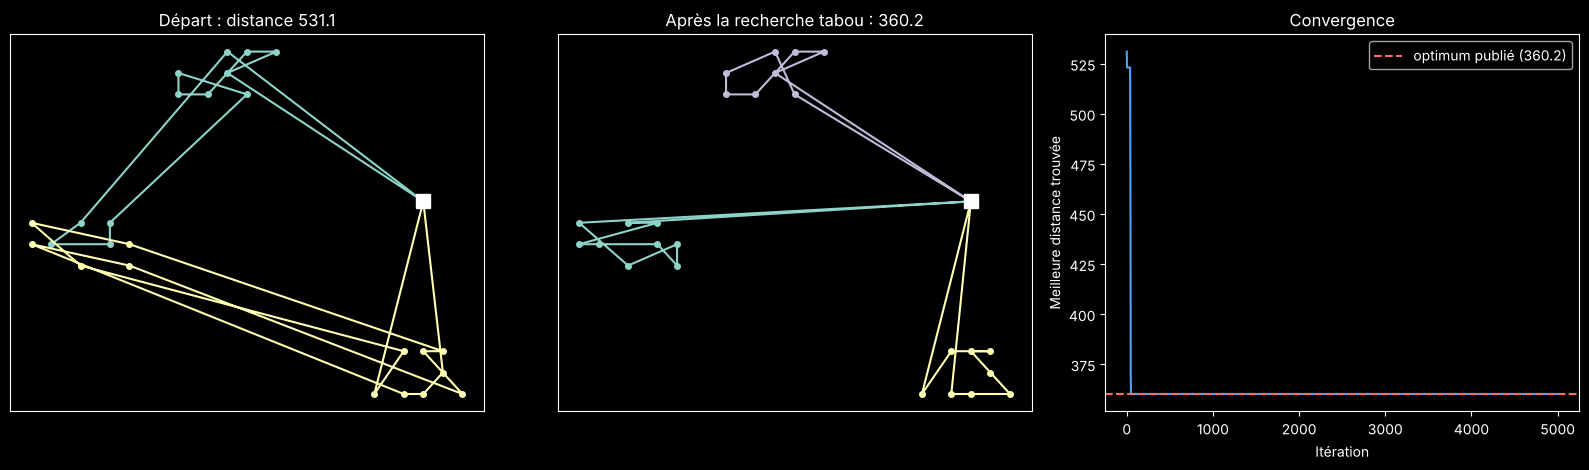

In [6]:
print(f"Temps de calcul : {secondes:.1f} s | solution valide : {cv.verifier_solution(resultat['solution'], demo)}")

coords = vrplib.read_instance(str(cv.DOSSIER_INSTANCES / str(taille) / f"{nom}.txt"),
                              instance_format="solomon")["node_coord"]

def dessiner(ax, solution, titre):
    for tournee in solution:
        ax.plot(coords[tournee, 0], coords[tournee, 1], "-o", markersize=4)
    ax.plot(coords[0, 0], coords[0, 1], "s", color="white", markersize=10)
    ax.set_title(titre)
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
dessiner(axes[0], demo["solution_depart"], f"Départ : distance {depart:.1f}")
dessiner(axes[1], resultat["solution"], f"Après la recherche tabou : {resultat['final']:.1f}")
axes[2].plot(resultat["historique"], color="#4ea1ff")
axes[2].axhline(optimum, color="#ff6b6b", linestyle="--", label=f"optimum publié ({optimum})")
axes[2].set_xlabel("Itération"); axes[2].set_ylabel("Meilleure distance trouvée")
axes[2].set_title("Convergence"); axes[2].legend()
plt.tight_layout(); plt.show()

**Lecture.** Le carré blanc est le dépôt ; chaque couleur est un camion. L'insertion construit des tournées qui se croisent et font de longs détours : son écart à l'optimum publié est d'environ 47 %. La recherche tabou démêle les tournées et retrouve l'optimum publié. Elle utilise un camion de plus que le départ : les mouvements DÉPLACER et ÉCHANGER LES FINS peuvent changer le nombre de camions, ce que le SWAP seul ne peut pas faire. La courbe de convergence montre que, sur cette petite instance, l'optimum est atteint en moins de 100 itérations ; le reste du temps, la recherche continue d'explorer sans trouver mieux.

# CHAPITRE V – Résultats, expérimentations et analyse

## V.1 Plan d'expérience

**Les questions posées.**

1. À quelle distance de l'optimum publié sont nos solutions, selon la classe et la taille des instances ?
2. Le résultat dépend-il du hasard de la recherche ?
3. Combien de temps faut-il ?
4. Que change le choix de l'objectif, durée ou distance ?

**Les instances.** Nous utilisons 12 instances de Solomon, 2 par classe, chacune en 25, 50 et 100 clients : **36 instances**.

- **C** : clients groupés par quartiers ; **R** : clients dispersés au hasard ; **RC** : un mélange des deux.
- **Type 1** : journée courte et petits camions, donc beaucoup de tournées courtes. **Type 2** : journée longue et gros camions, donc peu de longues tournées.

**Le critère de qualité.** Pour chacune de ces instances, la plus petite distance totale possible a été trouvée et **prouvée optimale** par des méthodes exactes, puis publiée (Kohl et al., 1999 ; Jepsen et al., 2008 ; Baldacci et al., 2011). Ces valeurs ne sont pas dans les fichiers d'instances : nous les avons recopiées dans le code (`OPTIMUMS_SOLOMON`). Notre écart, le **gap**, se calcule ainsi :

$$\text{gap} = 100 \times \frac{\text{distance trouvée} - \text{optimum publié}}{\text{optimum publié}}$$

| Instance | Classe | 25 clients | 50 clients | 100 clients |
| :--- | :--- | ---: | ---: | ---: |
| C101 | C1 | 191,3 | 362,4 | 827,3 |
| C102 | C1 | 190,3 | 361,4 | 827,3 |
| C201 | C2 | 214,7 | 360,2 | 589,1 |
| C202 | C2 | 214,7 | 360,2 | 589,1 |
| R101 | R1 | 617,1 | 1044,0 | 1637,7 |
| R102 | R1 | 547,1 | 909,0 | 1466,6 |
| R201 | R2 | 463,3 | 791,9 | 1143,2 |
| R202 | R2 | 410,5 | 698,5 | 1029,6 |
| RC101 | RC1 | 461,1 | 944,0 | 1619,8 |
| RC102 | RC1 | 351,8 | 822,5 | 1457,4 |
| RC201 | RC2 | 360,2 | 684,8 | 1261,8 |
| RC202 | RC2 | 338,0 | 613,6 | 1092,3 |

**Les réglages, identiques pour toutes les exécutions.**

| Paramètre | Valeur |
| :--- | :--- |
| Itérations (critère d'arrêt) | 5 000 |
| Essais tirés par itération | 250 |
| Voisins proches par client | 10 |
| Taille de la liste tabou | 120 |
| Part des DÉPLACER vers un camion libre | 5 % |
| Objectif | distance |

**Les graines.** La recherche tire des clients au hasard. La **graine** fixe ce tirage : avec la même graine, on refait exactement le même calcul. Chaque instance est lancée avec **3 graines** (1, 2 et 3), soit 3 exécutions différentes : 108 exécutions en tout. Nous donnons la moyenne et l'écart-type.

**Le temps.** C'est le temps réel de la recherche tabou seule, mesuré avec `time.perf_counter`, en secondes, sur un même ordinateur.

Ces résultats sont produits par le mode `solomon` du code (environ 20 minutes) et enregistrés dans `resultats_cvrptw/04_solomon/`. Le notebook relit ces fichiers.

## V.2 Validation sur les instances de Solomon

In [7]:
res = pd.read_csv("resultats_cvrptw/04_solomon/resultats_solomon.csv", sep=";", encoding="utf-8-sig")
print(len(res), "exécutions,", int(res["valide"].sum()), "solutions valides")

res.groupby("clients").agg(
    gap_insertion_moyen=("gap_insertion_pourcent", "mean"),
    gap_tabou_moyen=("gap_pourcent", "mean"),
    ecart_type=("gap_pourcent", "std"),
    gap_max=("gap_pourcent", "max"),
    temps_moyen_s=("temps_secondes", "mean"),
)

108 exécutions, 108 solutions valides


,gap_insertion_moyen,gap_tabou_moyen,ecart_type,gap_max,temps_moyen_s
clients,,,,,
25,24.63,1.97,3.97,14.66,11.04
50,41.14,4.02,3.62,17.57,9.88
100,41.59,5.37,2.88,14.69,12.14


**Interprétation.** Les 108 solutions sont valides. La recherche tabou divise l'écart de la solution de départ par 8 à 12 : de 25 % à 2 % à 25 clients, et de 42 % à 5,4 % à 100 clients. Le gap moyen reste **sous 10 % à toutes les tailles**, mais il augmente avec la taille : avec le même nombre d'itérations, il y a plus de clients à bien placer. Le gap maximal (entre 14 et 18 %) montre que quelques exécutions restent loin de l'optimum : elles sont étudiées plus bas.

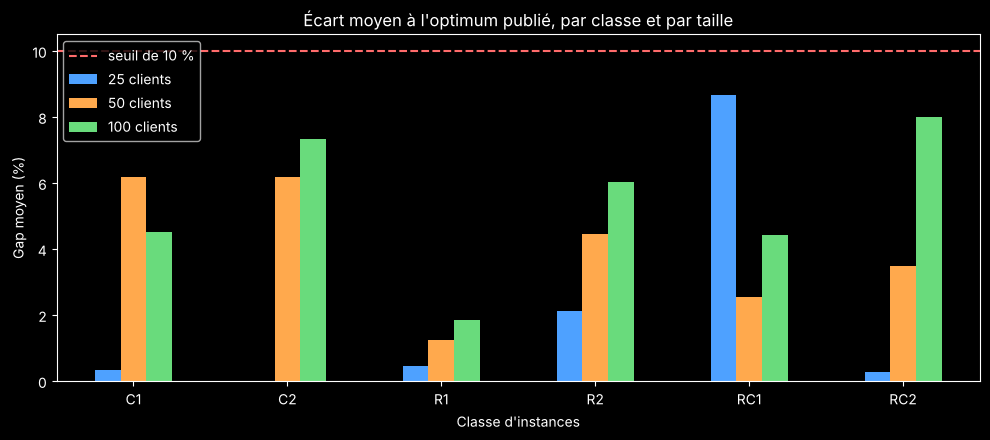

clients,25,50,100
classe,,,
C1,0.33,6.17,4.51
C2,0.00,6.17,7.34
R1,0.46,1.24,1.86
R2,2.11,4.46,6.05
RC1,8.66,2.56,4.44
RC2,0.28,3.49,8.00


In [8]:
classes = ["C1", "C2", "R1", "R2", "RC1", "RC2"]
gaps = res.pivot_table(index="classe", columns="clients", values="gap_pourcent", aggfunc="mean").loc[classes]

ax = gaps.plot.bar(figsize=(10, 4.5), rot=0, color=["#4ea1ff", "#ffa94d", "#69db7c"])
ax.axhline(10, color="#ff6b6b", linestyle="--", label="seuil de 10 %")
ax.set_xlabel("Classe d'instances"); ax.set_ylabel("Gap moyen (%)")
ax.set_title("Écart moyen à l'optimum publié, par classe et par taille")
ax.legend(["seuil de 10 %", "25 clients", "50 clients", "100 clients"])
plt.tight_layout(); plt.show()
gaps

**Interprétation.**

- Toutes les moyennes par classe sont **sous 10 %**.
- Les classes **R1** (clients dispersés, tournées courtes) sont les mieux résolues : moins de 2 % à toutes les tailles. Les tournées sont courtes, et nos mouvements locaux suffisent à bien les organiser.
- À 100 clients, les classes de **type 2** sont les plus difficiles (C2 7,3 %, R2 6,0 %, RC2 8,0 %). Leurs tournées sont longues, avec beaucoup de clients par camion : une petite modification change peu la tournée, et il faut beaucoup d'itérations pour la réorganiser.
- **RC1 à 25 clients** (8,7 %) est une exception : sur RC101 et RC102, certaines exécutions restent bloquées vers 14 %. La recherche trouve un bon plan, mais ne parvient pas à en sortir pour atteindre le meilleur.

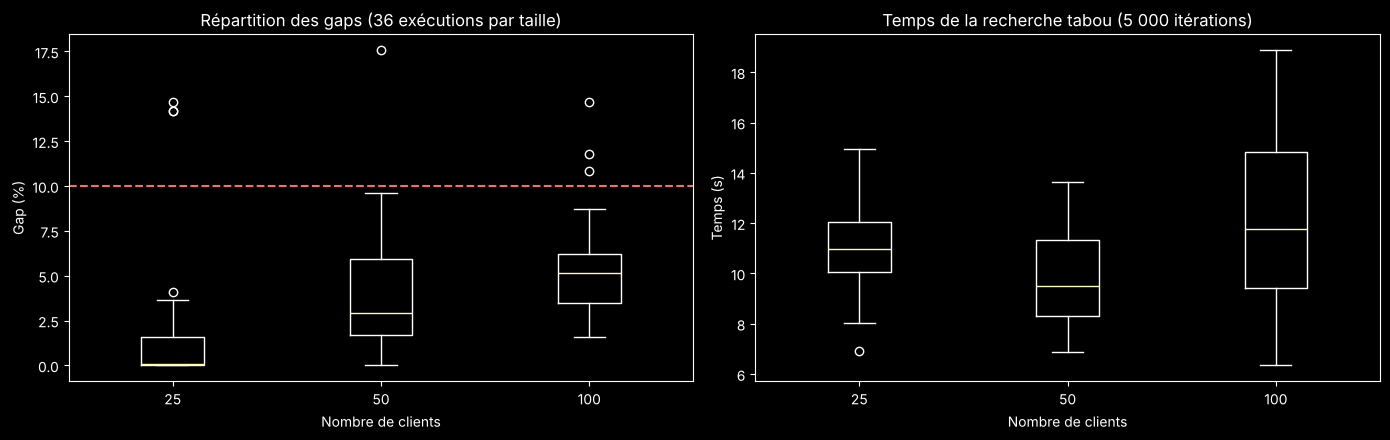

Exécutions sous 10 % : 94 %
Exécutions qui trouvent l'optimum publié : 19 sur 108


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
tailles = [25, 50, 100]
axes[0].boxplot([res.loc[res["clients"] == t, "gap_pourcent"] for t in tailles], tick_labels=tailles)
axes[0].axhline(10, color="#ff6b6b", linestyle="--")
axes[0].set_xlabel("Nombre de clients"); axes[0].set_ylabel("Gap (%)")
axes[0].set_title("Répartition des gaps (36 exécutions par taille)")

axes[1].boxplot([res.loc[res["clients"] == t, "temps_secondes"] for t in tailles], tick_labels=tailles)
axes[1].set_xlabel("Nombre de clients"); axes[1].set_ylabel("Temps (s)")
axes[1].set_title("Temps de la recherche tabou (5 000 itérations)")
plt.tight_layout(); plt.show()

print(f"Exécutions sous 10 % : {100 * (res['gap_pourcent'] < 10).mean():.0f} %")
print(f"Exécutions qui trouvent l'optimum publié : {(res['gap_pourcent'] < 0.01).sum()} sur {len(res)}")

**Interprétation.**

- **Qualité.** La boîte contient la moitié centrale des exécutions. Elle reste sous 10 % à toutes les tailles : 94 % des exécutions sont sous ce seuil. À 25 clients, la recherche retrouve souvent l'optimum publié. Les points isolés au-dessus de 10 % sont les quelques exécutions bloquées.
- **Robustesse.** L'écart-type est de 3 à 4 points. Pour la plupart des instances, les 3 graines donnent des résultats proches : le résultat dépend peu du hasard. RC101 et RC102 à 25 clients, et RC202 à 50 clients, font exception : une graine y est bien moins bonne que les autres.
- **Temps.** Le temps reste entre 6 et 19 secondes, et ne grandit presque pas avec le nombre de clients. Une itération ne vérifie qu'une ou deux tournées (chapitre III) : son coût dépend de la longueur des tournées, pas du nombre total de clients.

## V.3 Durée ou distance : que change l'objectif ?

Le cas ADEME demande de minimiser la **durée** des tournées : trajets, attentes et livraisons. Les optimums publiés sont des **distances**. Nous avons lancé la recherche deux fois sur les 12 instances à 25 clients : une fois en minimisant la distance, une fois en minimisant la durée. Les deux solutions sont mesurées dans les deux unités.

Ces résultats sont produits par le mode `objectifs` du code et enregistrés dans `resultats_cvrptw/05_duree_ou_distance/`.

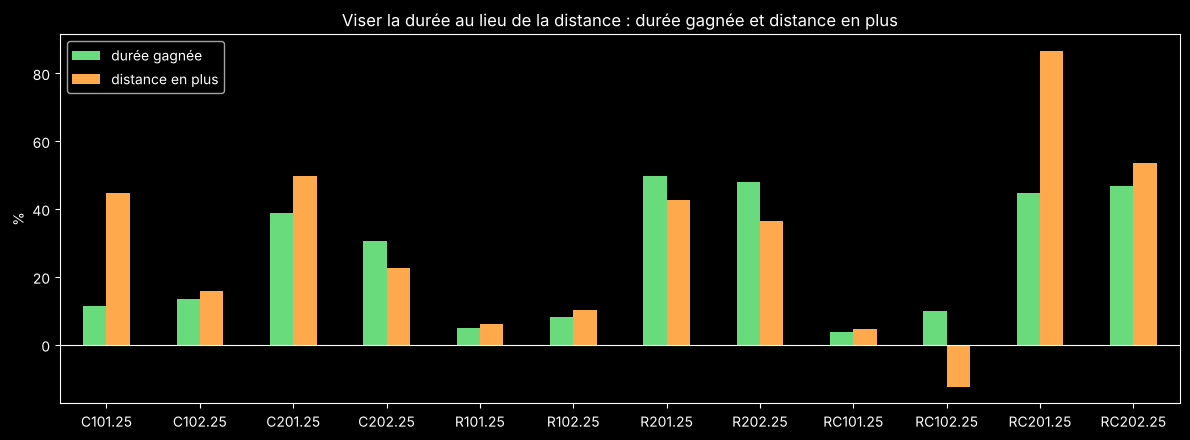

Moyenne : durée gagnée 25.9 %, distance en plus 30.1 %


In [10]:
obj = pd.read_csv("resultats_cvrptw/05_duree_ou_distance/duree_ou_distance.csv", sep=";", encoding="utf-8-sig")
obj = obj.set_index("instance")

ax = obj[["duree_gagnee_pourcent", "distance_en_plus_pourcent"]].plot.bar(
    figsize=(12, 4.5), rot=0, color=["#69db7c", "#ffa94d"])
ax.axhline(0, color="white", linewidth=0.8)
ax.set_ylabel("%"); ax.set_xlabel("")
ax.set_title("Viser la durée au lieu de la distance : durée gagnée et distance en plus")
ax.legend(ax.containers, ["durée gagnée", "distance en plus"])
plt.tight_layout(); plt.show()

print(f"Moyenne : durée gagnée {obj['duree_gagnee_pourcent'].mean():.1f} %, "
      f"distance en plus {obj['distance_en_plus_pourcent'].mean():.1f} %")

**Interprétation.**

- En visant la durée, on gagne en moyenne **26 % de durée**, mais on roule **30 % de plus**. Les deux objectifs donnent des plans de tournées vraiment différents.
- La raison est l'**attente**. La solution la plus courte en distance fait souvent arriver les camions avant l'ouverture des clients : ils attendent. Viser la durée pousse à éviter ces attentes, par exemple en ajoutant un camion ou en faisant un détour pour livrer un autre client pendant ce temps.
- L'écart est fort sur les instances de **type 2** (journée longue, fenêtres larges) : 30 à 50 % de durée gagnée. Il est faible sur le **type 1** (fenêtres serrées, peu d'attente possible) : 4 à 13 %.
- **RC102** est un cas particulier : la solution « durée » est aussi plus courte en distance (352,0 contre 401,6). La recherche en distance était restée bloquée sur cette instance (le cas vu en V.2) ; en partant dans une autre direction, la recherche en durée a trouvé un meilleur plan.

Pour l'ADEME, dont le but est de réduire la consommation d'énergie, ce résultat compte : 30 % de distance en plus, c'est plus de carburant consommé. Le choix de l'objectif dépend donc de ce que l'on veut réduire en priorité : les heures de travail des chauffeurs (durée) ou la consommation (distance).

## V.4 Études sur instances générées

*Partie rédigée par Thomas : études 1 à 3 du code (60 instances générées selon 4 scénarios et 3 tailles, influence des paramètres de la recherche tabou, passage à 500, 1 000 et 2 000 clients). Résultats dans `resultats_cvrptw/01_instances/`, `02_parametres/` et `03_grandes_tailles/`.*

## V.5 Limites

- **La taille.** Le gap est mesuré jusqu'à 100 clients. Lors d'un essai complémentaire sur les instances de Gehring et Homberger (mêmes règles que Solomon, de 200 à 1 000 clients), avec les mêmes réglages, l'écart moyen monte à environ 14 % à 200 clients et 23 % à 400. Pour descendre sous 10 % à ces tailles, il faudrait plus d'itérations et un mécanisme de diversification plus fort.
- **Les blocages.** Sur quelques exécutions (RC101 et RC102 à 25 clients, RC202 à 50 et 100), la recherche reste bloquée entre 14 et 18 %. Une mémoire à long terme, ou une perturbation qui repart de la meilleure solution, permettrait d'en sortir.
- **Le trafic.** Les temps de trajet sont fixes : le trafic variable selon l'heure n'est pas modélisé.
- **Le nombre de camions.** Nous minimisons la distance ou la durée, pas le nombre de camions, et nous ne comparons pas notre nombre de camions à celui des solutions publiées.

# CONCLUSION ET RECOMMANDATIONS

Nous avons modélisé les tournées de l'ADEME comme un **CVRPTW** : capacité des camions, fenêtres horaires, temps de livraison et attente possible. Le problème est **NP-difficile** : une méthode exacte devient trop lente quand le nombre de clients grandit.

Nous avons donc retenu une **recherche tabou**. Elle part d'une insertion gloutonne, puis améliore les tournées avec trois mouvements (SWAP, DÉPLACER, ÉCHANGER LES FINS) tentés entre clients proches, une liste tabou et un critère d'aspiration. 9 cas de test vérifient les règles du problème une par une.

Sur 36 instances de Solomon, lues avec `vrplib`, l'écart moyen à l'optimum publié est de **2,0 % à 25 clients, 4,0 % à 50 et 5,4 % à 100**, en 6 à 19 secondes par exécution. Toutes les solutions sont valides.

**Recommandations.**

1. **Choisir l'objectif selon le but.** Viser la durée réduit le temps de travail d'environ 26 %, mais augmente la distance d'environ 30 %. Pour réduire la consommation d'énergie, la distance est le meilleur objectif ; un objectif mixte (distance plus une part de la durée) serait un bon compromis.
2. **Garder plusieurs exécutions.** Lancer 3 graines et garder la meilleure solution évite la plupart des blocages, pour un temps de calcul qui reste faible.
3. **Pour aller plus loin :** ajouter une perturbation ou une mémoire à long terme pour les grandes tailles, intégrer des temps de trajet qui dépendent de l'heure (trafic), et minimiser aussi le nombre de camions.

# RÉFÉRENCES

**Problème et complexité**

1. Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254-265.
2. Toth, P., et Vigo, D. (dir.) (2014). *Vehicle Routing: Problems, Methods, and Applications* (2e éd.). SIAM.
3. Karp, R. M. (1972). Reducibility among combinatorial problems. Dans *Complexity of Computer Computations*, 85-103. Plenum Press.
4. Garey, M. R., et Johnson, D. S. (1979). *Computers and Intractability: A Guide to the Theory of NP-Completeness*. W. H. Freeman.

**Méthode**

5. Glover, F. (1986). Future paths for integer programming and links to artificial intelligence. *Computers & Operations Research*, 13(5), 533-549.
6. Glover, F., et Laguna, M. (1997). *Tabu Search*. Kluwer Academic Publishers.
7. Cordeau, J.-F., Laporte, G., et Mercier, A. (2001). A unified tabu search heuristic for vehicle routing problems with time windows. *Journal of the Operational Research Society*, 52(8), 928-936.
8. Potvin, J.-Y., et Rousseau, J.-M. (1995). An exchange heuristic for routeing problems with time windows. *Journal of the Operational Research Society*, 46(12), 1433-1446.
9. Savelsbergh, M. W. P. (1985). Local search in routing problems with time windows. *Annals of Operations Research*, 4, 285-305.

**Résultats de référence et outils**

10. Kohl, N., Desrosiers, J., Madsen, O. B. G., Solomon, M. M., et Soumis, F. (1999). 2-path cuts for the vehicle routing problem with time windows. *Transportation Science*, 33(1), 101-116.
11. Jepsen, M., Petersen, B., Spoorendonk, S., et Pisinger, D. (2008). Subset-row inequalities applied to the vehicle-routing problem with time windows. *Operations Research*, 56(2), 497-511.
12. Baldacci, R., Mingozzi, A., et Roberti, R. (2011). New route relaxation and pricing strategies for the vehicle routing problem. *Operations Research*, 59(5), 1269-1283.
13. Gehring, H., et Homberger, J. (1999). A parallel hybrid evolutionary metaheuristic for the vehicle routing problem with time windows. *Proceedings of EUROGEN99*, 57-64.
14. SINTEF, *Solomon benchmark* : https://www.sintef.no/projectweb/top/vrptw/solomon-benchmark/
15. Bibliothèque `vrplib` : https://github.com/PyVRP/VRPLIB

**Cours**

16. Workshops CESI : Graphes et modélisation ; Problème NP-complet ; Méthodes exactes ; Métaheuristiques.